# TP #3 — Machines à vecteurs de support (SVM)
**Apprentissage Automatique Avancé** — Prof. Abdelouahab Moussaoui

- **Exercice 1** : SVM linéaire et SVM à noyau gaussien sur **Iris**
- **Exercice 2** : SVM sur **Digits** (gamma, ACP, recherche par grille, nombre de composantes)

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import svm, datasets
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.precision', 4)

def plot_regions(clf, X, y, ax, title, cmap=plt.cm.tab10, nc=10):
    # Surface de décision d'un classifieur entraîné sur 2 variables + points de test
    x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
    y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=.3, cmap=cmap, vmin=0, vmax=nc-1)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, vmin=0, vmax=nc-1, edgecolors='k', s=25)
    ax.set_title(title, fontsize=10)

---
# Exercice 1 — Jeu de données Iris
On ne conserve d'abord que les **2 premiers attributs** (longueur et largeur des sépales) pour pouvoir visualiser, et **50 % des données** pour l'évaluation.

In [2]:
iris = datasets.load_iris()
X, y = iris.data[:, :2], iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)
print(X_train.shape, X_test.shape)

C = 1.0   # paramètre de régularisation
lin_svc = svm.LinearSVC(C=C, max_iter=20000)
lin_svc.fit(X_train, y_train)

(75, 2) (75, 2)


,"max_iter max_iter: int, default=1000The maximum number of iterations to be run.",20000
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0


## Question 1 — Score en test, puis avec les 4 attributs

LinearSVC, 2 attributs : score test = 0.6667  | score entraînement = 0.8667


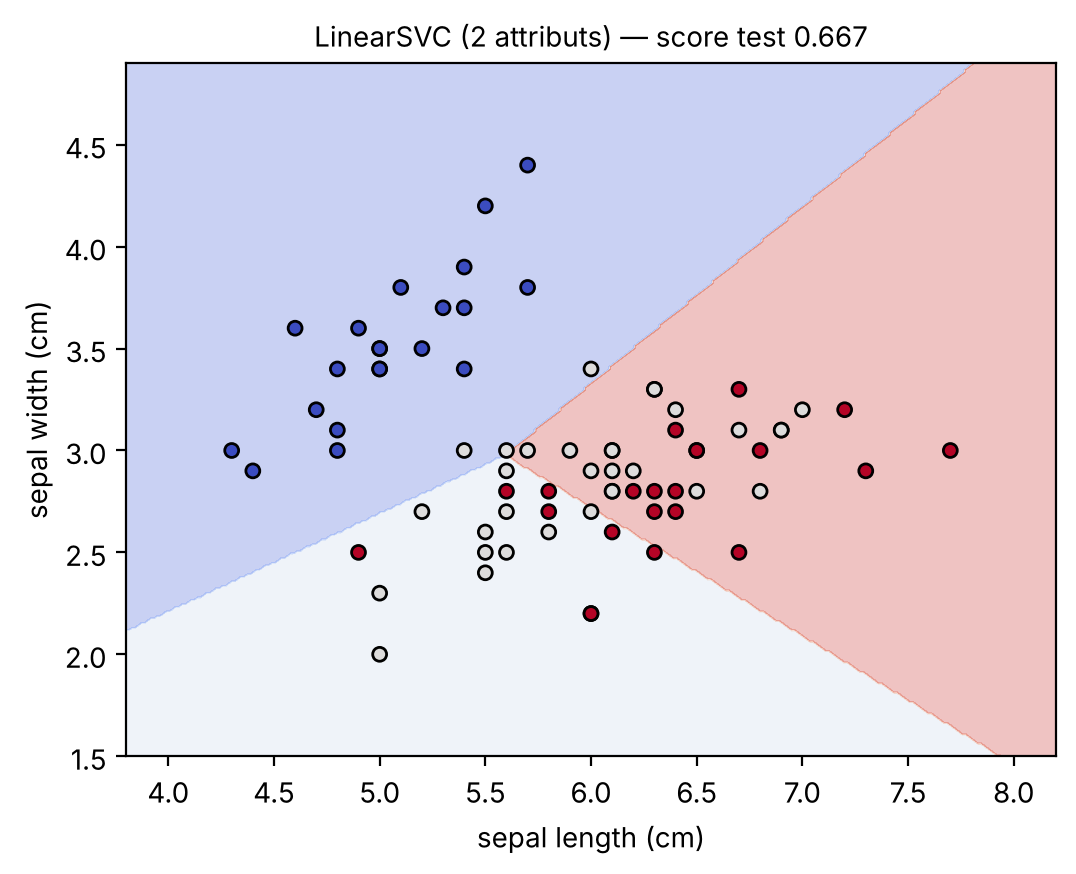

LinearSVC, 4 attributs : score test = 0.9200  | score entraînement = 0.9733


Sur 20 découpages : 2 attributs 0.742 ± 0.054  |  4 attributs 0.945 ± 0.023


In [3]:
score2 = lin_svc.score(X_test, y_test)
print(f"LinearSVC, 2 attributs : score test = {score2:.4f}  | score entraînement = {lin_svc.score(X_train, y_train):.4f}")

fig, ax = plt.subplots(figsize=(6, 4.5))
plot_regions(lin_svc, X_test, y_test, ax, f"LinearSVC (2 attributs) — score test {score2:.3f}", cmap=plt.cm.coolwarm, nc=3)
ax.set_xlabel(iris.feature_names[0]); ax.set_ylabel(iris.feature_names[1]); plt.show()

# Nouvelle SVM linéaire avec les 4 attributs
X4_train, X4_test, y4_train, y4_test = train_test_split(iris.data, iris.target, test_size=0.5, random_state=0)
lin_svc4 = svm.LinearSVC(C=C, max_iter=20000).fit(X4_train, y4_train)
score4 = lin_svc4.score(X4_test, y4_test)
print(f"LinearSVC, 4 attributs : score test = {score4:.4f}  | score entraînement = {lin_svc4.score(X4_train, y4_train):.4f}")

# Robustesse : le résultat dépend-il du découpage ? (20 découpages aléatoires)
s2, s4 = [], []
for rs in range(20):
    a, b, c_, d = train_test_split(iris.data, iris.target, test_size=0.5, random_state=rs)
    s2.append(svm.LinearSVC(C=C, max_iter=20000).fit(a[:, :2], c_).score(b[:, :2], d))
    s4.append(svm.LinearSVC(C=C, max_iter=20000).fit(a, c_).score(b, d))
print(f"Sur 20 découpages : 2 attributs {np.mean(s2):.3f} ± {np.std(s2):.3f}  |  4 attributs {np.mean(s4):.3f} ± {np.std(s4):.3f}")

**Commentaire.**
- **2 attributs (sépales) : score test = 0,667** (entraînement 0,867). **4 attributs : score test = 0,92** (entraînement 0,973). Sur 20 découpages aléatoires, la moyenne passe de **0,742 ± 0,054** à **0,945 ± 0,023** : le score **augmente nettement**, et ce n'est pas un effet du découpage particulier utilisé ci-dessus.
- **Pourquoi ?** Avec les seuls sépales, les classes *versicolor* et *virginica* se **chevauchent fortement** : aucune droite ne peut les séparer correctement (seule *setosa* est isolée). Les attributs de **pétales** (longueur, largeur) séparent bien mieux les trois espèces : en les ajoutant, les classes deviennent presque linéairement séparables et le classifieur linéaire a beaucoup plus d'information discriminante.
- Avec 75 exemples de test, un point de score ≈ 1 fleur : les écarts observés ici (≈ 25 points) sont largement au-delà de ce bruit.

## Question 2 — SVM linéaire sur Digits
Le jeu `load_digits` contient **1797 images** (8×8) : il n'est pas nécessaire de sous-échantillonner (le conseil des 10 000 échantillons vise MNIST complet). On choisit C par **validation croisée sur l'entraînement**, puis on évalue sur le test.

(1797, 64) (1797,)


,CV (5 plis),train,test
C,,,
0.0001,0.8434,0.8594,0.8333
0.0003,0.8761,0.8838,0.8611
0.0010,0.8963,0.9088,0.9028
0.0032,0.9242,0.9360,0.9250
0.0100,0.9409,0.9499,0.9444
0.0316,0.9520,0.9645,0.9556
0.1000,0.9631,0.9770,0.9639
0.3162,0.9680,0.9861,0.9556
1.0000,0.9673,0.9923,0.9583


Meilleur C selon la validation croisée : 0.3162  -> score test = 0.9556
(meilleur score test absolu sur la grille : 0.9639, à ne pas utiliser pour choisir C)


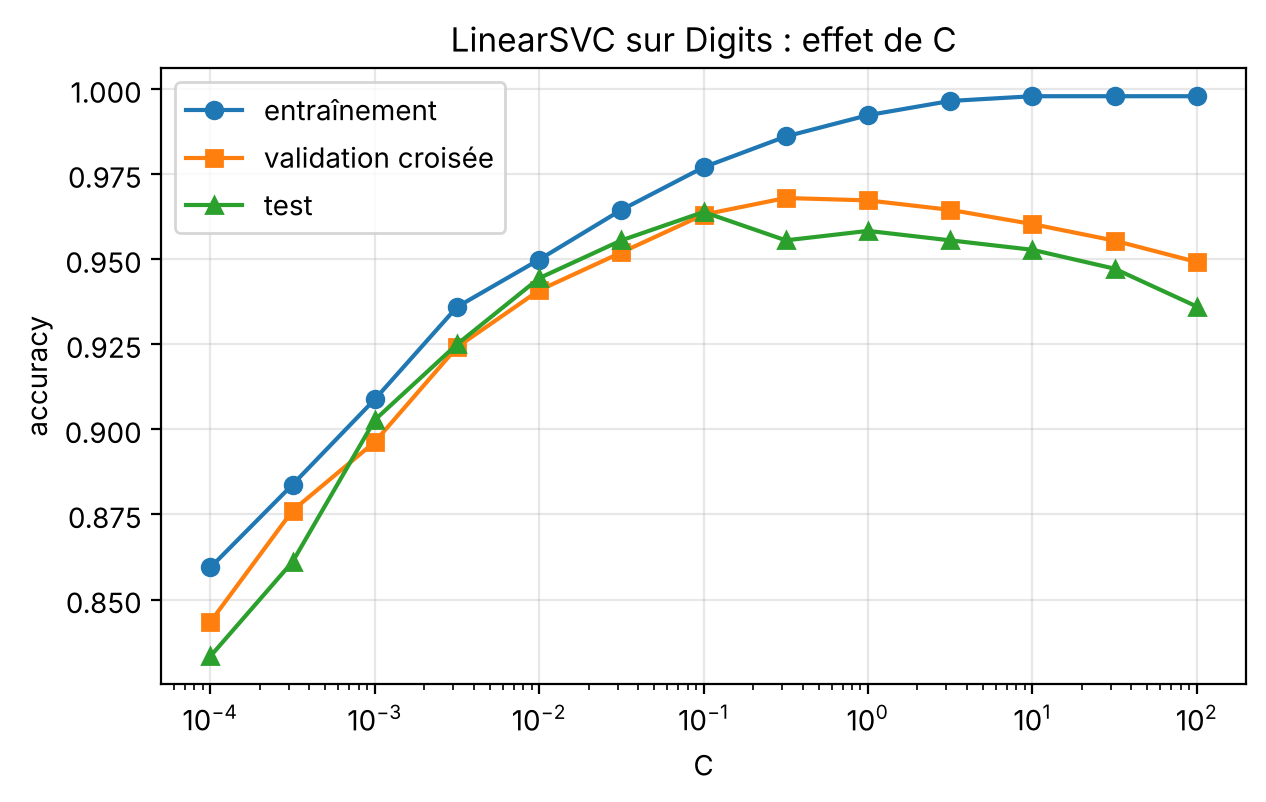

In [4]:
from sklearn.datasets import load_digits
digits = load_digits()
Xd, yd = digits.data, digits.target
print(Xd.shape, yd.shape)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.2, random_state=0)

# Les pixels sont dans [0, 16] : on les ramène dans [0, 1] pour la convergence de LinearSVC
Xd_train_s, Xd_test_s = Xd_train / 16.0, Xd_test / 16.0

Cs = np.logspace(-4, 2, 13)
cv_scores, test_scores, train_scores = [], [], []
for Cv in Cs:
    clf = svm.LinearSVC(C=Cv, max_iter=50000)
    cv_scores.append(cross_val_score(clf, Xd_train_s, yd_train, cv=5).mean())
    clf.fit(Xd_train_s, yd_train)
    train_scores.append(clf.score(Xd_train_s, yd_train)); test_scores.append(clf.score(Xd_test_s, yd_test))

res = pd.DataFrame({'C': Cs, 'CV (5 plis)': cv_scores, 'train': train_scores, 'test': test_scores}).set_index('C')
display(res)
best_C = Cs[int(np.argmax(cv_scores))]
print(f"Meilleur C selon la validation croisée : {best_C:.4g}  -> score test = {test_scores[int(np.argmax(cv_scores))]:.4f}")
print(f"(meilleur score test absolu sur la grille : {max(test_scores):.4f}, à ne pas utiliser pour choisir C)")

plt.figure(figsize=(7, 4))
plt.semilogx(Cs, train_scores, 'o-', label='entraînement')
plt.semilogx(Cs, cv_scores, 's-', label='validation croisée')
plt.semilogx(Cs, test_scores, '^-', label='test')
plt.xlabel('C'); plt.ylabel('accuracy'); plt.legend(); plt.grid(alpha=.3)
plt.title('LinearSVC sur Digits : effet de C'); plt.show()

**Commentaire (choix de C).**
- **C trop petit** (10⁻⁴ à 10⁻³) : régularisation trop forte, le modèle **sous-apprend** (test 83 % à 90 %).
- **C intermédiaire** (≈ 0,1 à 3) : plateau de généralisation. Le meilleur C selon la validation croisée est **C ≈ 0,32** (CV 96,8 %, **test 95,6 %**).
- **C grand** (≥ 10) : le score d'entraînement monte à 99,8 % alors que la validation croisée et le test **baissent** (CV 94,9 % pour C = 100) : **surapprentissage**.
- Le C est choisi sur la validation croisée de l'entraînement, **pas sur le test** (le meilleur score de test de la grille, 96,4 %, est un peu supérieur mais sélectionner dessus serait biaisé). Les valeurs de C dépendent de l'échelle des données : ici les pixels sont ramenés dans [0, 1].

## Question 3 — Classification multi-classe avec LibLinear

In [5]:
lin = svm.LinearSVC(C=best_C, max_iter=50000).fit(Xd_train_s, yd_train)
print("LinearSVC (LibLinear) : classes =", lin.classes_)
print("  coef_ shape =", lin.coef_.shape, "-> 1 hyperplan (64 poids) par classe")
print("  decision_function shape =", lin.decision_function(Xd_test_s).shape)

# Prédiction = classe dont l'hyperplan donne le score le plus élevé (un contre tous)
manuel = lin.classes_[np.argmax(lin.decision_function(Xd_test_s), axis=1)]
print("  predict == argmax(decision_function) :", np.array_equal(manuel, lin.predict(Xd_test_s)))

# Comparaison avec libsvm (SVC) qui utilise un-contre-un
ovo = svm.SVC(kernel='linear', decision_function_shape='ovo').fit(Xd_train_s, yd_train)
print("SVC (libsvm), decision_function 'ovo' shape =", ovo.decision_function(Xd_test_s).shape, "(= 10*9/2 = 45 classifieurs binaires)")

LinearSVC (LibLinear) : classes = [0 1 2 3 4 5 6 7 8 9]
  coef_ shape = (10, 64) -> 1 hyperplan (64 poids) par classe
  decision_function shape = (360, 10)
  predict == argmax(decision_function) : True
SVC (libsvm), decision_function 'ovo' shape = (360, 45) (= 10*9/2 = 45 classifieurs binaires)


**Réponse.** Les SVM sont binaires ; **LibLinear (`LinearSVC`) gère le multi-classe par la stratégie « un contre tous » (*one-vs-rest*, OvR)** : pour **10 classes (MNIST), il entraîne 10 classifieurs binaires**, le classifieur *k* séparant la classe *k* de l'ensemble des 9 autres. On obtient une matrice `coef_` de forme (10, nb_variables) ; pour un nouvel exemple, on calcule les 10 scores $w_k\cdot x+b_k$ et on prédit la **classe de score maximal** (vérifié ci-dessus). 

À titre de comparaison, `SVC` (LibSVM) utilise la stratégie **« un contre un »** (*one-vs-one*) : 10×9/2 = **45** classifieurs binaires, chacun entraîné sur seulement deux classes, puis vote majoritaire. `LinearSVC` propose aussi `multi_class='crammer_singer'`, une formulation multi-classe jointe, plus lente et rarement meilleure.

## Question 4 — Iris avec un noyau gaussien : effet de gamma et de C
(2 attributs, mêmes données d'entraînement/test que la Question 1.)

Score TEST (lignes : gamma, colonnes : C)


C,0.1,1.0,10.0,100.0,1000.0
gamma,,,,,
0.01,0.2800,0.5333,0.7333,0.7200,0.7200
0.10,0.5467,0.7200,0.7200,0.7067,0.7200
1.00,0.6667,0.7200,0.6933,0.6933,0.7067
10.00,0.4800,0.7067,0.6933,0.7067,0.7067
100.00,0.2800,0.5467,0.5467,0.5467,0.5467


Score ENTRAÎNEMENT (lignes : gamma, colonnes : C)


C,0.1,1.0,10.0,100.0,1000.0
gamma,,,,,
0.01,0.3867,0.6800,0.8533,0.8667,0.8667
0.10,0.6800,0.8533,0.8667,0.8533,0.8667
1.00,0.7600,0.8667,0.8800,0.9067,0.9333
10.00,0.6533,0.9067,0.9333,0.9467,0.9600
100.00,0.3867,0.9467,0.9600,0.9600,0.9600


Rappel — SVM linéaire : test = 0.6667
SVC noyau gaussien par défaut (C=1, gamma='scale'=0.207) : test = 0.7200


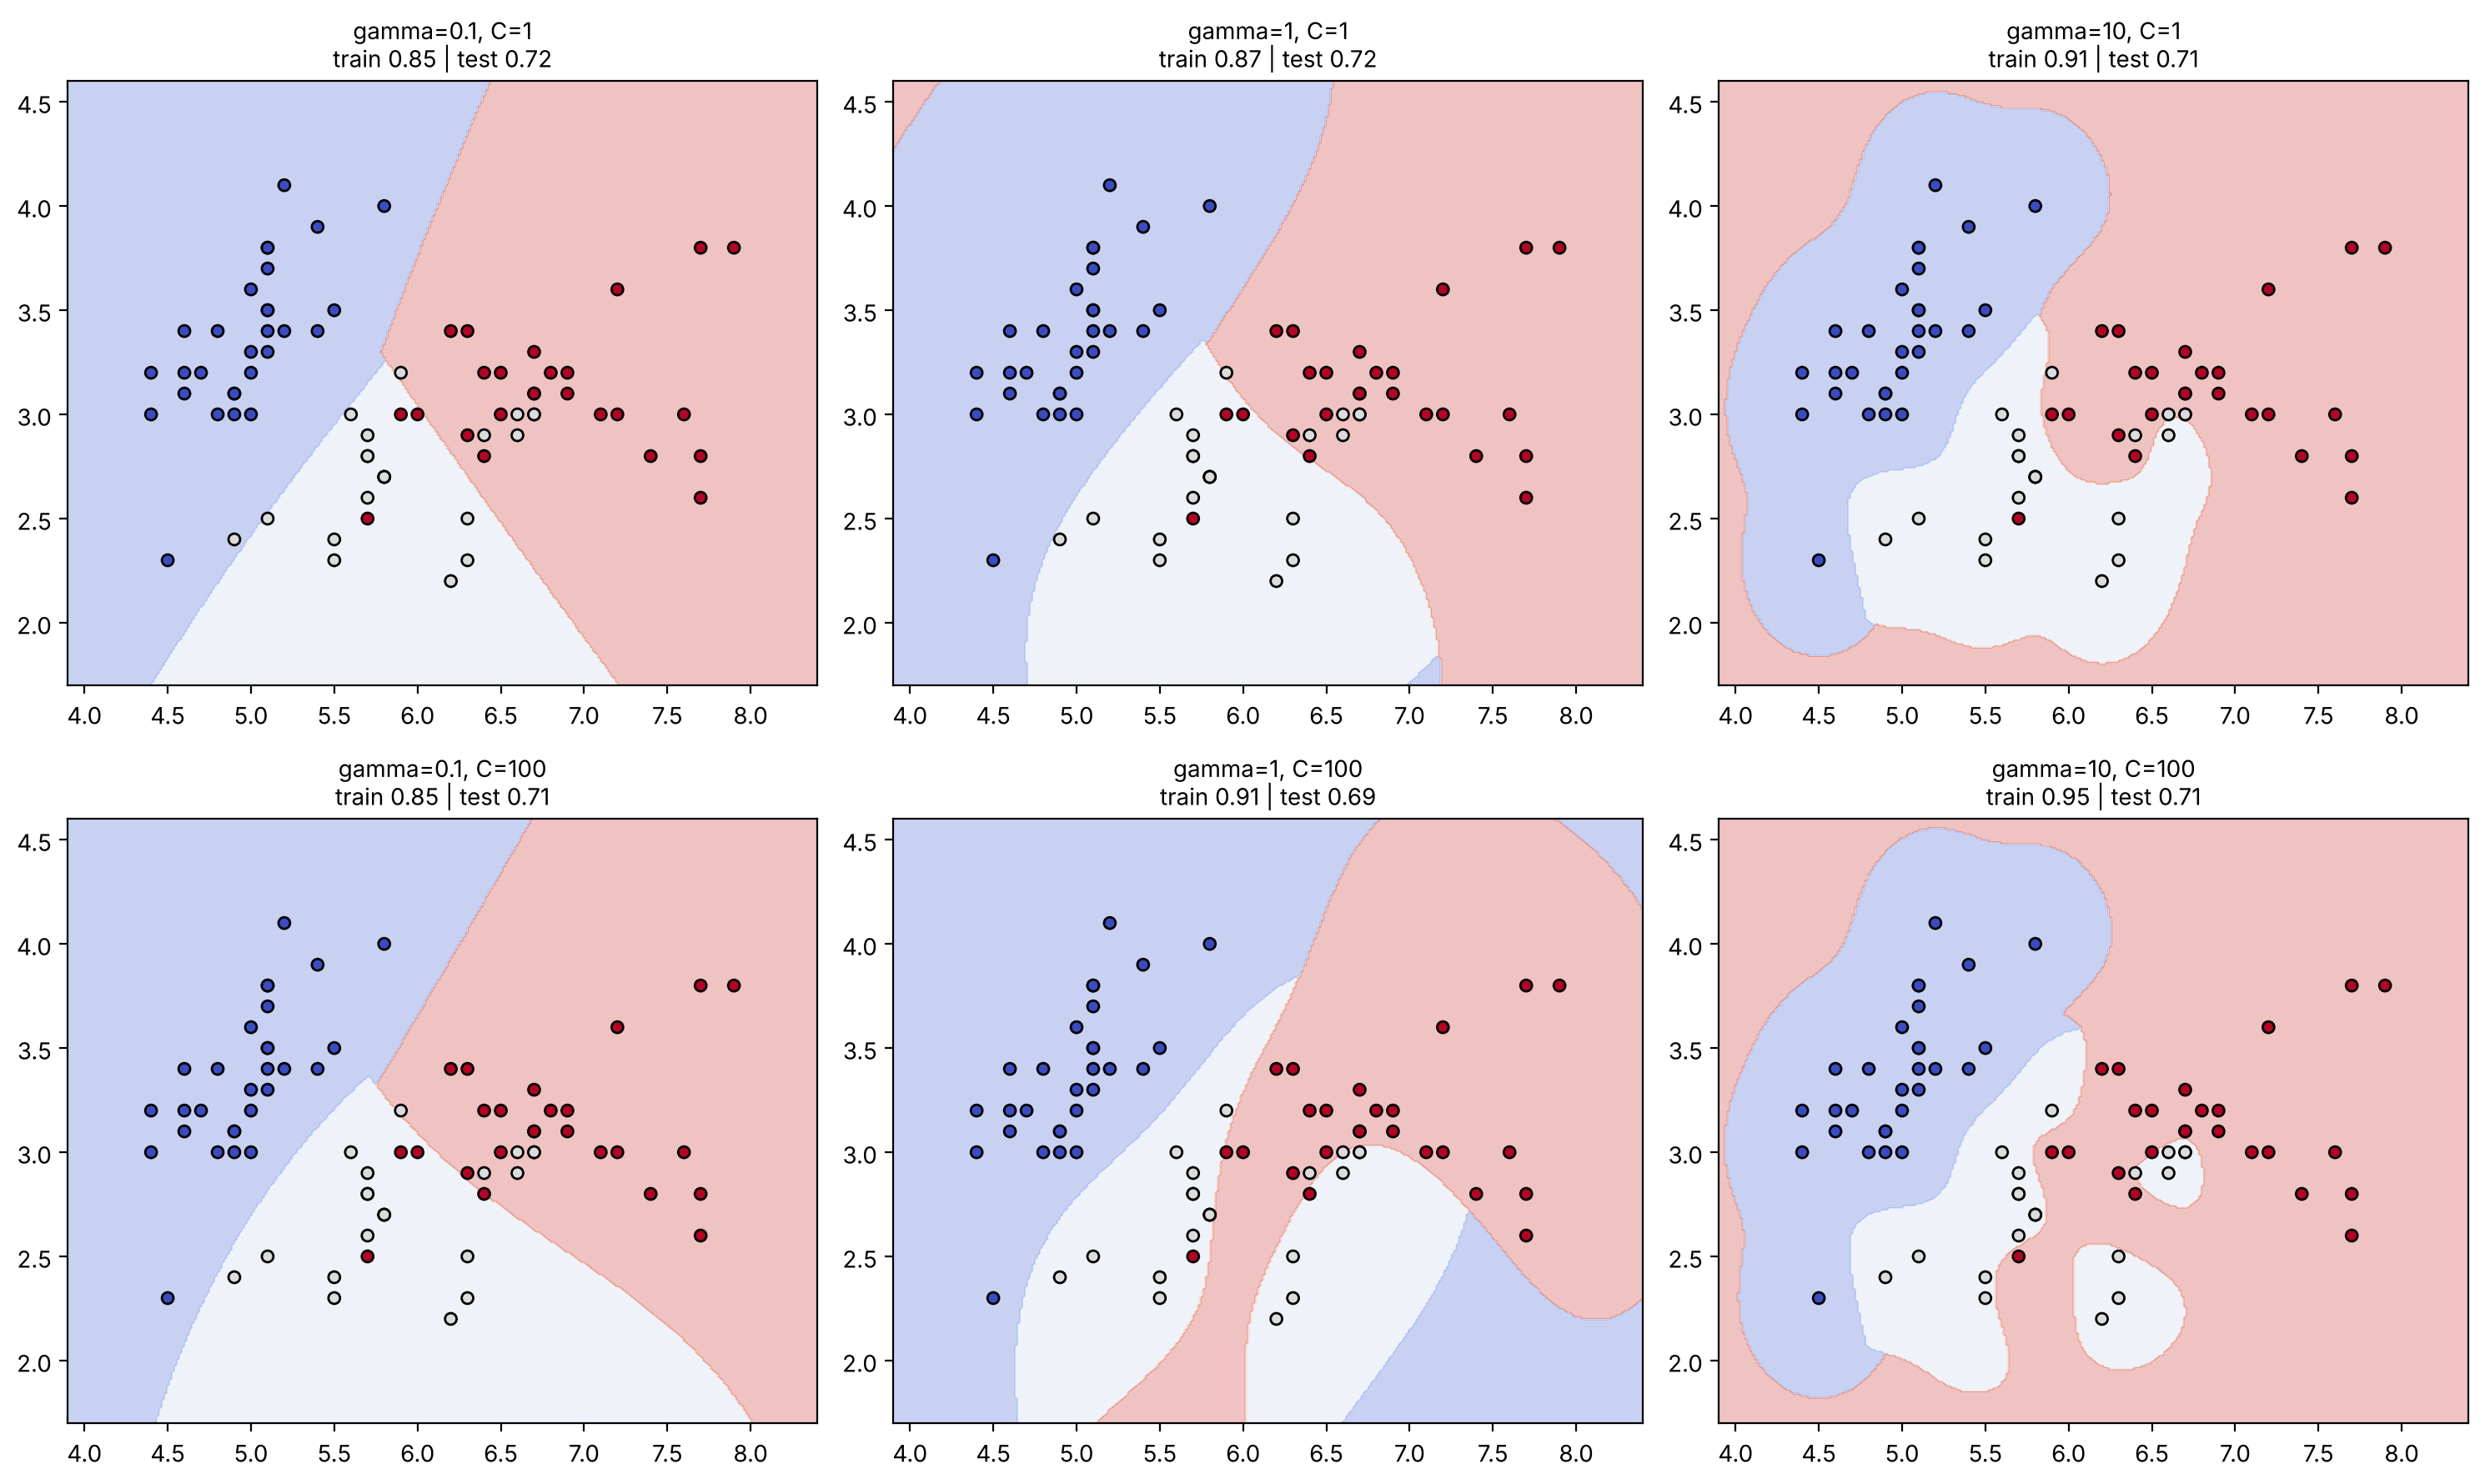

In [6]:
gammas_i = [0.01, 0.1, 1, 10, 100]
Cs_i = [0.1, 1, 10, 100, 1000]
test_tab = pd.DataFrame(index=pd.Index(gammas_i, name='gamma'), columns=pd.Index(Cs_i, name='C'), dtype=float)
train_tab = test_tab.copy()
for g in gammas_i:
    for Cv in Cs_i:
        m = svm.SVC(kernel='rbf', gamma=g, C=Cv).fit(X_train, y_train)
        test_tab.loc[g, Cv] = m.score(X_test, y_test); train_tab.loc[g, Cv] = m.score(X_train, y_train)
print("Score TEST (lignes : gamma, colonnes : C)");         display(test_tab)
print("Score ENTRAÎNEMENT (lignes : gamma, colonnes : C)"); display(train_tab)
print(f"Rappel — SVM linéaire : test = {score2:.4f}")
m_def = svm.SVC(kernel='rbf').fit(X_train, y_train)
print(f"SVC noyau gaussien par défaut (C=1, gamma='scale'={m_def._gamma:.3f}) : test = {m_def.score(X_test, y_test):.4f}")

combos = [(0.1, 1), (1, 1), (10, 1), (0.1, 100), (1, 100), (10, 100)]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (g, Cv) in zip(axes.ravel(), combos):
    m = svm.SVC(kernel='rbf', gamma=g, C=Cv).fit(X_train, y_train)
    plot_regions(m, X_train, y_train, ax, f"gamma={g}, C={Cv}\ntrain {m.score(X_train, y_train):.2f} | test {m.score(X_test, y_test):.2f}", cmap=plt.cm.coolwarm, nc=3)
plt.tight_layout(); plt.show()

**Commentaire (gamma et C).**
- **gamma** règle la **portée d'influence** de chaque vecteur de support : petit gamma = frontière très lisse (presque linéaire), grand gamma = frontière très sinueuse collée aux points d'apprentissage. **C** règle la pénalisation des erreurs d'entraînement : petit C = marge large et tolérante, grand C = marge étroite qui cherche à classer correctement tous les points.
- **Sous-apprentissage :** gamma = 0,01 avec C = 0,1 donne seulement 0,28 en test (0,39 en entraînement) : modèle trop lisse et trop contraint.
- **Surapprentissage :** pour gamma = 100, le score d'entraînement monte à 0,95–0,96 alors que le test tombe à **0,55** ; pour gamma = 10 avec C ≥ 10, l'entraînement atteint 0,93–0,96 pour un test de 0,69–0,71. On voit sur les graphiques les petites « îles » de décision autour de points isolés.
- **Zone raisonnable :** gamma entre 0,1 et 1 et C entre 1 et 10, avec un test d'environ 0,69–0,72 (entraînement 0,85–0,88). Le noyau par défaut (C = 1, gamma = 'scale' ≈ 0,21) donne **0,72**, contre **0,667** pour la SVM linéaire : léger gain, mais le meilleur test de la table (0,733) ne diffère que de 1 à 2 fleurs sur 75, donc il ne faut pas sur-interpréter les petits écarts.
- **Limite :** quel que soit le noyau, on plafonne vers 0,72–0,75, car les deux attributs de sépales ne séparent pas *versicolor* et *virginica* (cf. Question 1 : 0,92 avec les 4 attributs). Un noyau plus flexible ne crée pas d'information absente des données.

---
# Exercice 2 — Jeu de données Digits
## Question 1 — SVM linéaire et SVM à noyau gaussien ; le paramètre gamma

In [7]:
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.2, random_state=0)

print("Valeurs de gamma dans scikit-learn :")
print(f"  gamma='scale' = 1 / (n_features * X.var()) = 1 / ({Xd_train.shape[1]} * {Xd_train.var():.3f}) = {1/(Xd_train.shape[1]*Xd_train.var()):.6f}")
print(f"  gamma='auto'  = 1 / n_features             = 1 / {Xd_train.shape[1]} = {1/Xd_train.shape[1]:.6f}")

lin_d = svm.SVC(kernel='linear').fit(Xd_train, yd_train)
print(f"\nSVM linéaire (SVC kernel='linear') : test = {lin_d.score(Xd_test, yd_test):.4f}")
for g in ('scale', 'auto'):
    m = svm.SVC(kernel='rbf', gamma=g).fit(Xd_train, yd_train)
    print(f"SVM gaussien, gamma='{g}'        : train = {m.score(Xd_train, yd_train):.4f} | test = {m.score(Xd_test, yd_test):.4f}")

Valeurs de gamma dans scikit-learn :
  gamma='scale' = 1 / (n_features * X.var()) = 1 / (64 * 36.249) = 0.000431
  gamma='auto'  = 1 / n_features             = 1 / 64 = 0.015625

SVM linéaire (SVC kernel='linear') : test = 0.9778
SVM gaussien, gamma='scale'        : train = 0.9944 | test = 0.9917


SVM gaussien, gamma='auto'        : train = 1.0000 | test = 0.3250


,train,test
gamma,,
1.0000e-06,0.1072,0.0806
3.1623e-06,0.5087,0.4167
1.0000e-05,0.9123,0.9028
3.1623e-05,0.9569,0.9556
1.0000e-04,0.9784,0.9806
3.1623e-04,0.9923,0.9917
1.0000e-03,0.9993,0.9917
3.1623e-03,1.0000,0.9833
1.0000e-02,1.0000,0.7778


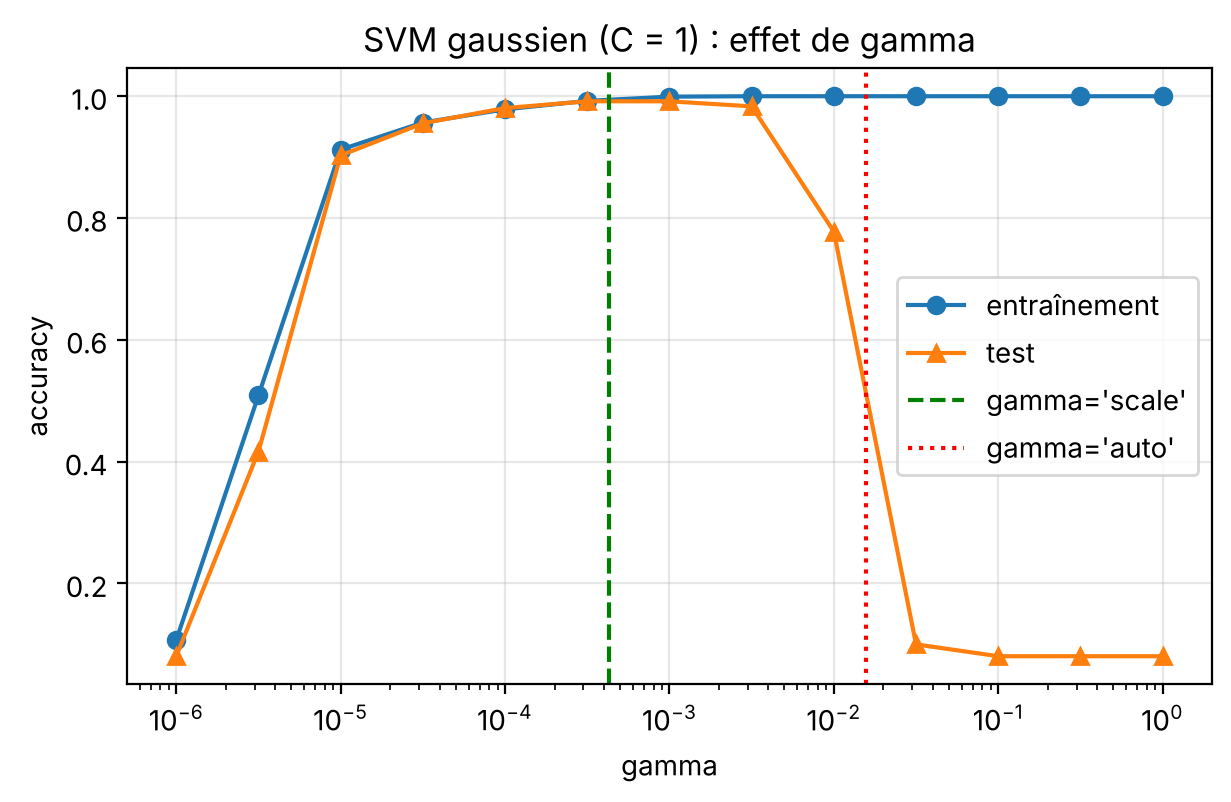

In [8]:
gammas = np.logspace(-6, 0, 13)
tr, te = [], []
for g in gammas:
    m = svm.SVC(kernel='rbf', gamma=g, C=1.0).fit(Xd_train, yd_train)
    tr.append(m.score(Xd_train, yd_train)); te.append(m.score(Xd_test, yd_test))
display(pd.DataFrame({'gamma': gammas, 'train': tr, 'test': te}).set_index('gamma'))

plt.figure(figsize=(7, 4))
plt.semilogx(gammas, tr, 'o-', label='entraînement')
plt.semilogx(gammas, te, '^-', label='test')
plt.axvline(1/(64*Xd_train.var()), c='g', ls='--', label="gamma='scale'")
plt.axvline(1/64, c='r', ls=':', label="gamma='auto'")
plt.xlabel('gamma'); plt.ylabel('accuracy'); plt.legend(); plt.grid(alpha=.3)
plt.title('SVM gaussien (C = 1) : effet de gamma'); plt.show()

**Commentaire.**
- **Rôle de gamma :** dans le noyau gaussien $K(x,x')=\exp(-\gamma\|x-x'\|^2)$, $\gamma$ est l'inverse du carré de la portée d'influence d'un exemple. **gamma trop petit** : frontière trop lisse, sous-apprentissage (test 8 % pour 10⁻⁶, 90 % pour 10⁻⁵). **gamma trop grand** : chaque exemple n'influence que son voisinage immédiat, d'où un entraînement à 100 % mais un test qui s'effondre (77,8 % pour 10⁻², puis 8–10 %, niveau du hasard, dès 3·10⁻²).
- **Plateau de bonne généralisation :** gamma entre 10⁻⁴ et 3·10⁻³ (test 98,1 % à 99,2 %).
- **gamma = 'scale'** vaut $1/(n_{\text{features}}\cdot \text{Var}(X))$ = 1/(64 × 36,25) ≈ **4,3·10⁻⁴** : il **s'adapte à l'échelle des données**. Il se trouve dans le plateau : **test = 99,17 %**. C'est la valeur par défaut de scikit-learn.
- **gamma = 'auto'** vaut $1/n_{\text{features}}$ = 1/64 ≈ **1,6·10⁻²** : il ignore la variance des données (ici les pixels vont de 0 à 16). Résultat : entraînement 100 % mais **test 32,5 %**, un surapprentissage massif.
- **Linéaire vs gaussien :** la SVM linéaire (`SVC(kernel='linear')`, C = 1) atteint 97,78 % en test, contre 99,17 % pour le noyau gaussien avec gamma = 'scale' : un gain modeste (5 images de plus sur 360), à condition de bien choisir gamma.

## Question 2 — ACP (2 composantes), noyau gaussien et surface de décision

Variance expliquée par les 2 composantes : [0.1508 0.1401] -> cumul 0.2909
SVM linéaire (LinearSVC)        : train = 0.5525 | test = 0.4889


SVM gaussien (gamma='scale')    : train = 0.6820 | test = 0.6444


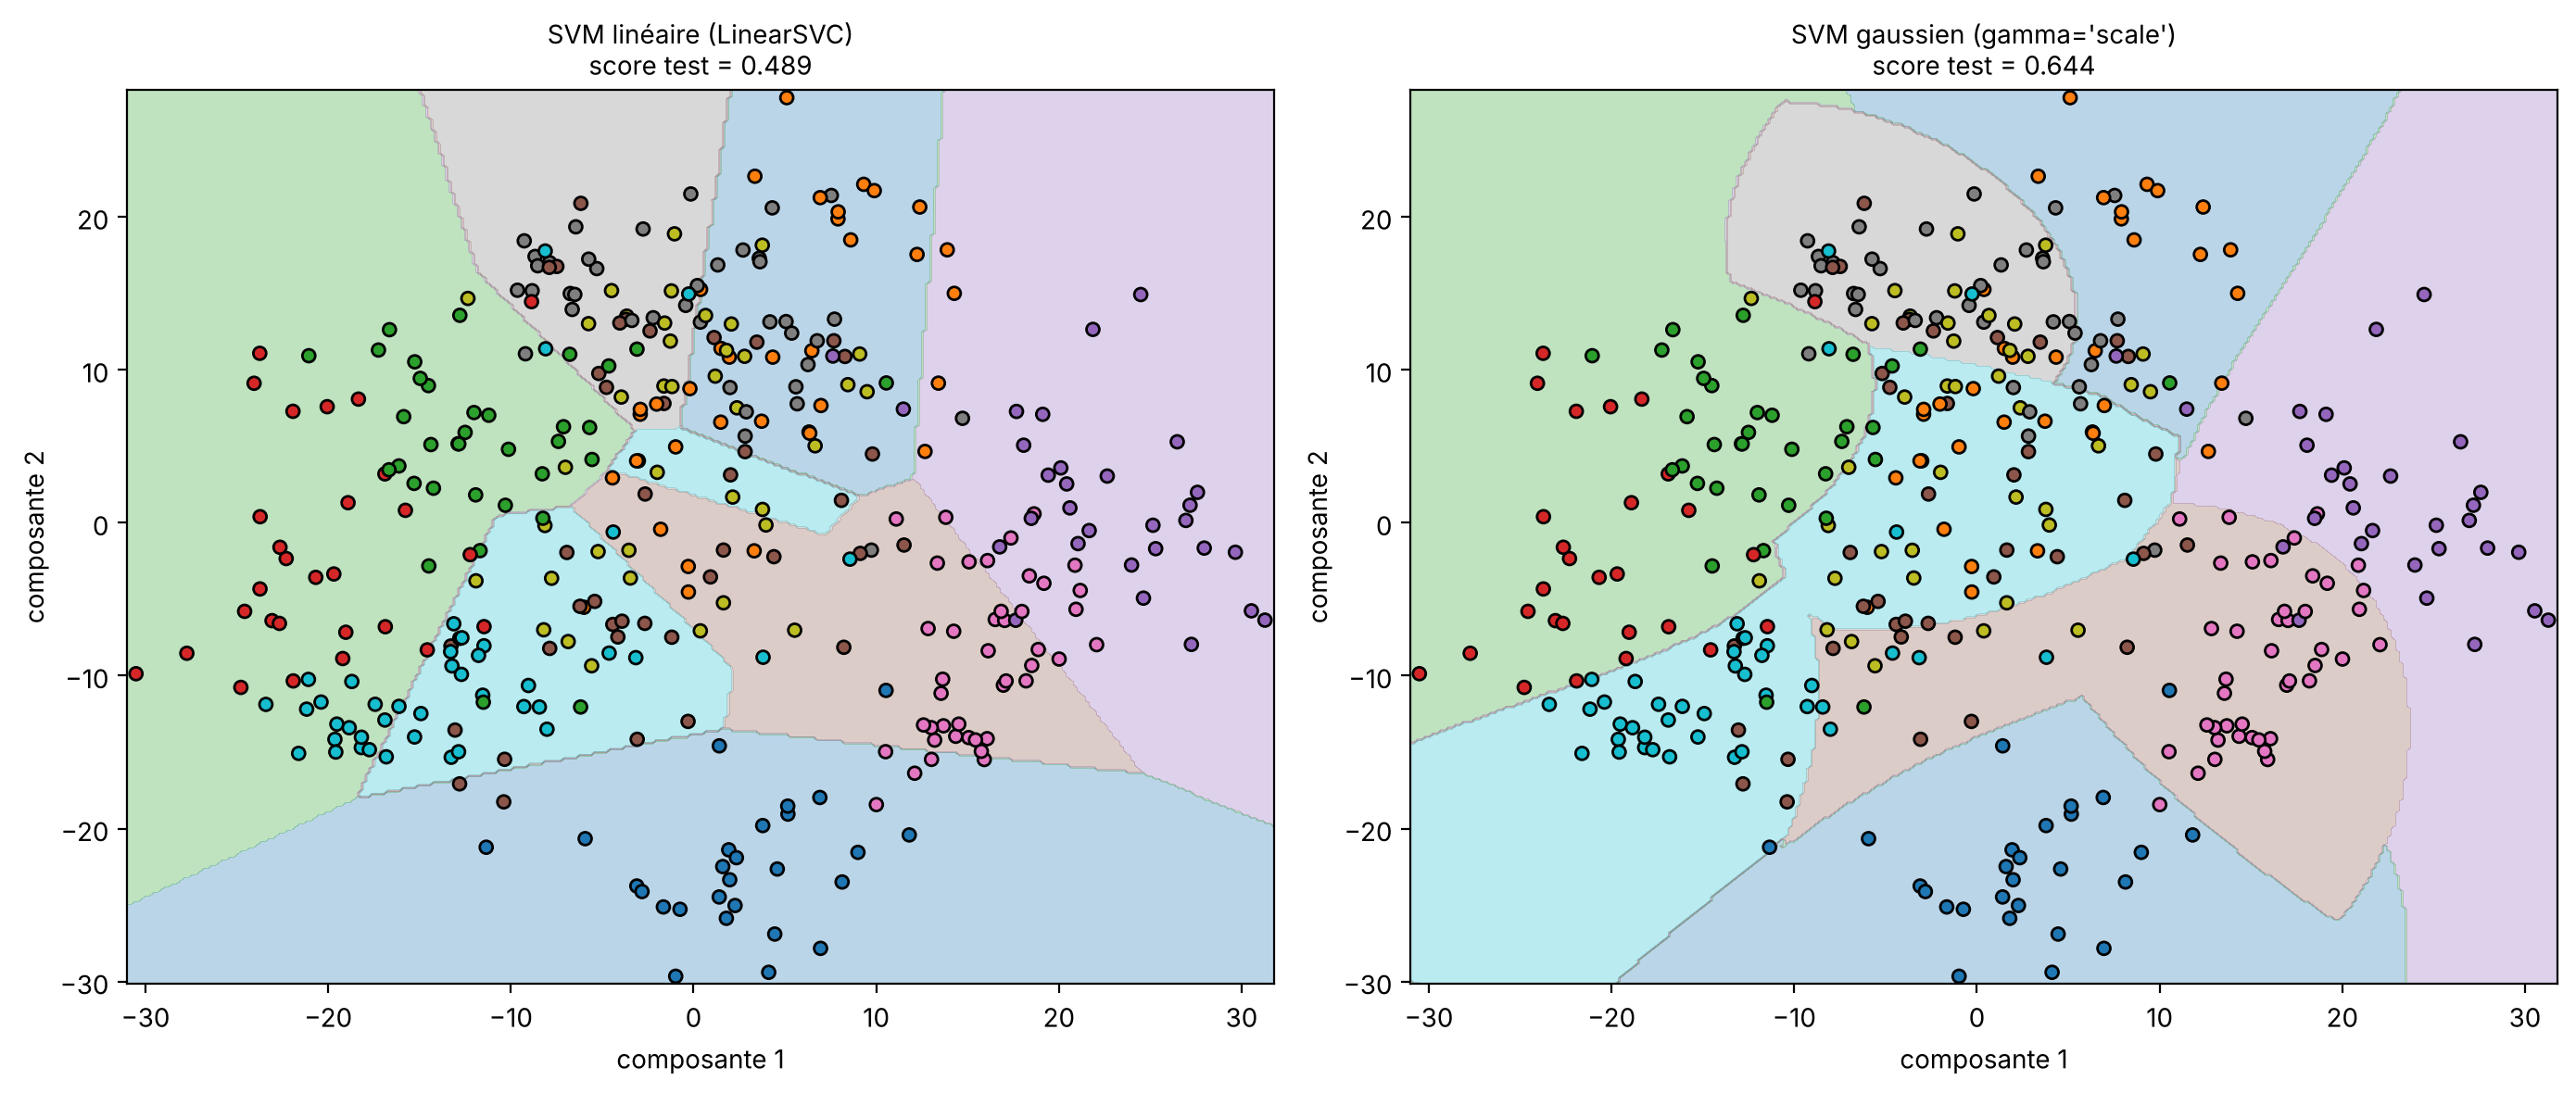

In [9]:
pca2 = PCA(n_components=2).fit(Xd_train)
P_train, P_test = pca2.transform(Xd_train), pca2.transform(Xd_test)
print("Variance expliquée par les 2 composantes :", pca2.explained_variance_ratio_, "-> cumul", round(pca2.explained_variance_ratio_.sum(), 4))

modeles = {
    "SVM linéaire (LinearSVC)": svm.LinearSVC(C=1.0, max_iter=50000),
    "SVM gaussien (gamma='scale')": svm.SVC(kernel='rbf', gamma='scale', C=1.0),
}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (nom, mod) in zip(axes, modeles.items()):
    mod.fit(P_train, yd_train)
    sc = mod.score(P_test, yd_test)
    plot_regions(mod, P_test, yd_test, ax, f"{nom}\nscore test = {sc:.3f}")
    ax.set_xlabel("composante 1"); ax.set_ylabel("composante 2")
    print(f"{nom:32s}: train = {mod.score(P_train, yd_train):.4f} | test = {sc:.4f}")
plt.tight_layout(); plt.show()

**Commentaire.**
- Les 2 premières composantes ne contiennent que **29,1 %** de la variance : l'ACP en 2 dimensions écrase les 10 classes les unes sur les autres.
- **SVM linéaire : test 48,9 %** (entraînement 55,3 %) : les frontières sont des droites (découpage en polygones convexes), inadaptées à des classes aussi imbriquées.
- **SVM à noyau gaussien : test 64,4 %** (entraînement 68,2 %) : les frontières non linéaires épousent mieux la forme des nuages, soit environ **+15 points** par rapport au linéaire.
- Dans les deux cas, scores d'entraînement et de test sont proches : le problème n'est pas le surapprentissage mais la **perte d'information** due à la projection en 2D (on est très loin des 99 % obtenus avec les 64 variables). L'ACP à 2 composantes est utile pour **visualiser**, pas pour classer ces données.

## Question 3 — Recherche par grille sur Digits complet (sans ACP)

In [10]:
param_grid = [
    {'kernel': ['linear'],  'C': [0.01, 0.1, 1, 10, 100]},
    {'kernel': ['poly'],    'C': [0.1, 1, 10, 100], 'degree': [2, 3, 4], 'gamma': ['scale']},
    {'kernel': ['rbf'],     'C': [0.1, 1, 10, 100, 1000], 'gamma': [1e-4, 1e-3, 3e-3, 1e-2, 'scale']},
    {'kernel': ['sigmoid'], 'C': [0.1, 1, 10, 100], 'gamma': [1e-4, 1e-3, 1e-2, 'scale']},
]
t0 = time.time()
grid = GridSearchCV(svm.SVC(), param_grid, cv=5, n_jobs=-1)
grid.fit(Xd_train, yd_train)
print(f"Recherche terminée en {time.time()-t0:.1f} s ({len(grid.cv_results_['params'])} combinaisons x 5 plis)")
print("Meilleurs paramètres :", grid.best_params_)
print(f"Meilleur score de validation croisée : {grid.best_score_:.4f}")
print(f"Score sur le jeu de test             : {grid.score(Xd_test, yd_test):.4f}")

r = pd.DataFrame(grid.cv_results_)
meil = r.loc[r.groupby('param_kernel')['mean_test_score'].idxmax(),
             ['param_kernel', 'params', 'mean_test_score']].set_index('param_kernel')
print("\nMeilleur résultat par noyau :")
display(meil)

Recherche terminée en 10.1 s (58 combinaisons x 5 plis)
Meilleurs paramètres : {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Meilleur score de validation croisée : 0.9923
Score sur le jeu de test             : 0.9917

Meilleur résultat par noyau :


,params,mean_test_score
param_kernel,,
linear,"{'C': 0.01, 'kernel': 'linear'}",0.9826
poly,"{'C': 1, 'degree': 3, 'gamma': 'scale', 'kerne...",0.9910
rbf,"{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}",0.9923
sigmoid,"{'C': 100, 'gamma': 0.0001, 'kernel': 'sigmoid'}",0.9805


**Commentaire.**
- **Meilleur modèle :** noyau **gaussien (rbf)**, **C = 10**, **gamma = 'scale'** (≈ 4,3·10⁻⁴) : score de validation croisée **99,23 %**, score en test **99,17 %**, cohérents entre eux.
- **Par noyau (meilleur score CV) :** rbf 99,23 % ; polynomial (degré 3, C = 1) 99,10 % ; linéaire 98,26 % (C = 0,01) ; sigmoïde 98,05 %. Les noyaux rbf et polynomial sont **pratiquement équivalents** (0,1 point d'écart, à ne pas sur-interpréter) ; le linéaire et le sigmoïde sont un peu en retrait.
- **Précautions :** les meilleures valeurs du noyau linéaire (C = 0,01) et du sigmoïde (C = 100, gamma = 10⁻⁴) sont **au bord de la grille testée** : on pourrait élargir la grille de ce côté. Avec 360 images de test, une image représente 0,28 point.

In [11]:
# (optionnel) meilleure valeur de n_components de l'ACP : ACP + SVM gaussien dans un pipeline
pipe = Pipeline([('pca', PCA()), ('svc', svm.SVC(kernel='rbf'))])
grid_pca = GridSearchCV(pipe, {'pca__n_components': [5, 10, 15, 20, 25, 30, 40, 64],
                               'svc__C': [1, 10, 100], 'svc__gamma': [1e-3, 3e-3, 1e-2, 'scale']},
                        cv=5, n_jobs=-1).fit(Xd_train, yd_train)
print("Meilleurs paramètres (ACP + SVM gaussien) :", grid_pca.best_params_)
print(f"Score CV : {grid_pca.best_score_:.4f} | score test : {grid_pca.score(Xd_test, yd_test):.4f}")

r2 = pd.DataFrame(grid_pca.cv_results_)
par_n = r2.groupby('param_pca__n_components')['mean_test_score'].max()
display(par_n.to_frame('meilleur score CV'))

Meilleurs paramètres (ACP + SVM gaussien) : {'pca__n_components': 25, 'svc__C': 10, 'svc__gamma': 'scale'}
Score CV : 0.9916 | score test : 0.9917


,meilleur score CV
param_pca__n_components,
5,0.9381
10,0.9819
15,0.9889
20,0.9896
25,0.9916
30,0.9910
40,0.9910
64,0.9910


**Commentaire (optionnel : n_components).** La meilleure valeur trouvée est **n_components = 25** (CV 99,16 %, test 99,17 %), mais 30, 40 ou 64 composantes donnent 99,10 % : **pas de différence réelle**. En dessous, la performance chute (20 : 98,96 % ; 15 : 98,89 % ; 10 : 98,19 % ; 5 : 93,81 %). L'ACP n'améliore donc pas la précision, mais **25 composantes suffisent** à égaler le modèle à 64 variables, soit une réduction de dimension d'un facteur ≈ 2,6 sans perte.

## Question 4 — Nombre minimal de composantes pour classer correctement ≥ 97 % des images

SVM gaussien utilisé : {'C': 10, 'gamma': 'scale'}


Nombre minimal de composantes avec accuracy (CV) >= 97 % : 9
   -> accuracy CV = 0.9777 | accuracy test = 0.9861
   -> variance expliquée par ces 9 composantes : 0.7105
   -> facteur de réduction de dimension : 64 / 9 = 7.11
Accuracy test avec les 64 variables (sans ACP) : 0.9917
Pour information, composantes nécessaires pour expliquer 97 % de la variance : 33


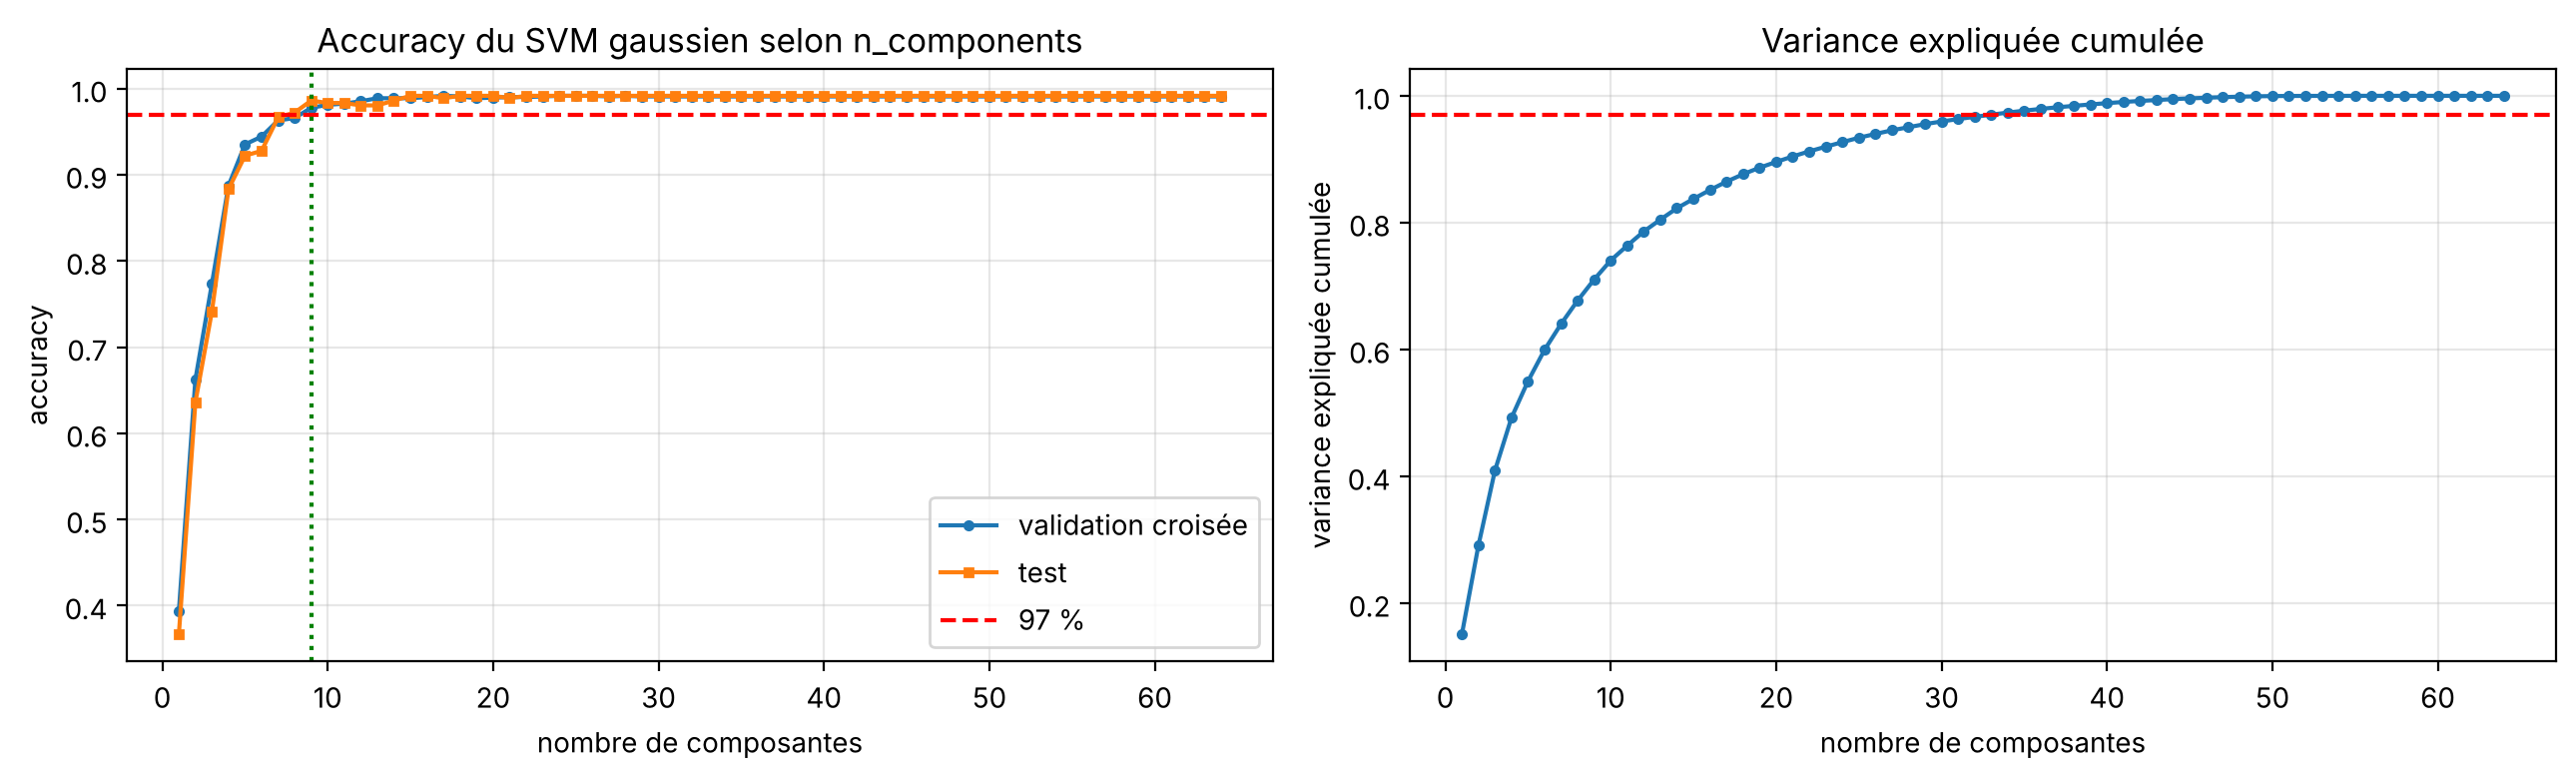

In [12]:
meilleur = {k.replace('svc__', ''): v for k, v in grid_pca.best_params_.items() if k.startswith('svc__')}
print("SVM gaussien utilisé :", meilleur)

pca_full = PCA().fit(Xd_train)
var_cum = np.cumsum(pca_full.explained_variance_ratio_)

ns = list(range(1, 65))
cv_n, test_n = [], []
for n in ns:
    p = Pipeline([('pca', PCA(n_components=n)), ('svc', svm.SVC(kernel='rbf', **meilleur))])
    cv_n.append(cross_val_score(p, Xd_train, yd_train, cv=5).mean())
    test_n.append(p.fit(Xd_train, yd_train).score(Xd_test, yd_test))
cv_n, test_n = np.array(cv_n), np.array(test_n)

n_min = int(ns[np.argmax(cv_n >= 0.97)]) if (cv_n >= 0.97).any() else None
print(f"Nombre minimal de composantes avec accuracy (CV) >= 97 % : {n_min}")
print(f"   -> accuracy CV = {cv_n[n_min-1]:.4f} | accuracy test = {test_n[n_min-1]:.4f}")
print(f"   -> variance expliquée par ces {n_min} composantes : {var_cum[n_min-1]:.4f}")
print(f"   -> facteur de réduction de dimension : 64 / {n_min} = {64/n_min:.2f}")
print(f"Accuracy test avec les 64 variables (sans ACP) : {test_n[-1]:.4f}")
print(f"Pour information, composantes nécessaires pour expliquer 97 % de la variance : {int(np.argmax(var_cum >= 0.97)) + 1}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(ns, cv_n, 'o-', ms=3, label='validation croisée'); ax[0].plot(ns, test_n, 's-', ms=3, label='test')
ax[0].axhline(0.97, c='r', ls='--', label='97 %'); ax[0].axvline(n_min, c='g', ls=':')
ax[0].set_xlabel("nombre de composantes"); ax[0].set_ylabel("accuracy"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[0].set_title("Accuracy du SVM gaussien selon n_components")
ax[1].plot(ns, var_cum, 'o-', ms=3); ax[1].axhline(0.97, c='r', ls='--')
ax[1].set_xlabel("nombre de composantes"); ax[1].set_ylabel("variance expliquée cumulée"); ax[1].grid(alpha=.3)
ax[1].set_title("Variance expliquée cumulée"); plt.tight_layout(); plt.show()

**Commentaire.**
- **Au minimum 9 composantes** suffisent pour classer correctement au moins 97 % des images (SVM gaussien C = 10, gamma = 'scale' : accuracy en validation croisée **97,77 %**, en test **98,61 %**), contre 99,17 % avec les 64 variables.
- **Facteur de réduction de dimension : 64 / 9 ≈ 7,1.**
- Ces 9 composantes ne représentent que **71,1 %** de la variance totale. Il en faudrait **33** pour expliquer 97 % de la variance : pour **classer**, il faut donc beaucoup moins de composantes que pour **reconstruire** les images, car une grande part de la variance restante est du bruit ou de la variabilité interne aux classes, peu utile à la discrimination.
- Remarque : les hyperparamètres du SVM sont fixés (issus de la grille) et non ré-optimisés pour chaque n ; le seuil de 97 % est évalué en validation croisée sur l'entraînement, puis confirmé en test.

---
# Synthèse
- **Iris :** avec les seuls attributs de sépales, aucune SVM ne dépasse ≈ 0,72–0,75 (classes imbriquées) ; avec les 4 attributs, la SVM linéaire atteint ≈ 0,92–0,95. Le noyau gaussien n'apporte que peu de gain sur 2 attributs et se met à surapprendre quand gamma et C sont grands.
- **Digits :** le choix de **gamma** est déterminant (`'scale'` ≈ 99 % en test, `'auto'` seulement 32,5 % ici). Meilleur modèle trouvé : noyau gaussien, C = 10, gamma = 'scale' (≈ **99,2 %**). L'ACP à 2 composantes est trop pauvre pour classer (64 %), alors que **9 composantes** suffisent déjà pour dépasser 97 %.